# Data analysis for ingest pipeline

Validate that TasteMender's imported audio-feature data is complete, internally consistent, and faithful to the original AcousticBrainz source data.

This work should identify any issues introduced during ingestion, transformation, normalization, or storage, and establish whether each feature provides enough useful variation to support recommendation ranking.

Links:
- https://acousticbrainz.org/datasets/accuracy

In [129]:
import os, uuid, sys, random
import django
import numpy as np
import numpy.typing as npt
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Enable access to Django project inside current notebook
PROJECT_PATH = os.path.dirname(os.path.abspath(""))
sys.path.append(PROJECT_PATH)
os.environ["DJANGO_SETTINGS_MODULE"] = "music_recommendation.settings"
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"
django.setup()

from recommend_api.models import GenreDortmund, GenreRosamerica, Track, Artist, Album

### Display genre distribution charts for 2 classifiers: Dortmund and Rosamerica

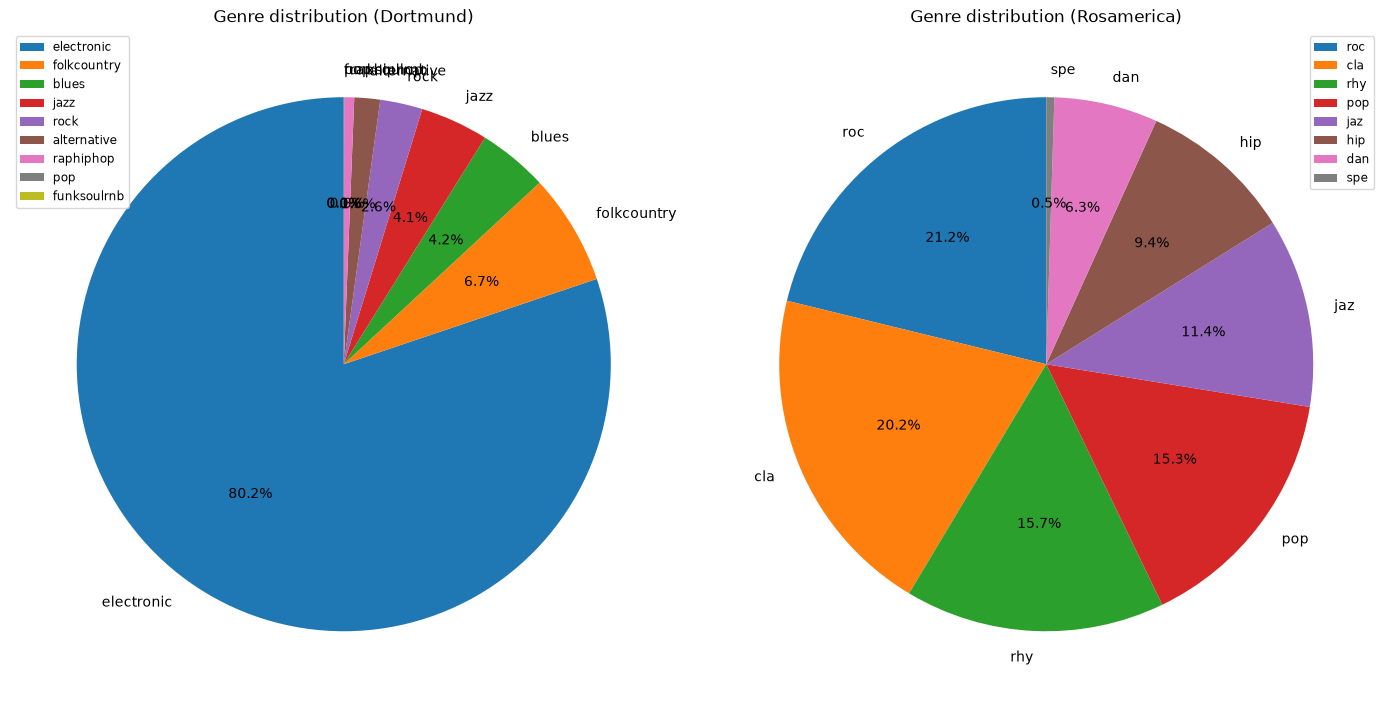

In [130]:
feature_store = np.load("../features_and_index.npz", allow_pickle=True, mmap_mode="r")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Pull genre codes for all tracks into a pandas Series
dort = pd.Series(feature_store["genre_dortmund"], name="count")
rosa = pd.Series(feature_store["genre_rosamerica"])

# Count and plot Dortmund, genre labels are stored in Django models
counts_dort = dort.value_counts()
dort_labels_by_code = dict(GenreDortmund.objects.values_list("code", "label"))
labels_dort = [dort_labels_by_code[code] for code in counts_dort.index]

axes[0].pie(counts_dort, labels=labels_dort, autopct="%1.1f%%", startangle=90)
axes[0].set_title("Genre distribution (Dortmund)")
axes[0].legend(labels_dort, loc="best", fontsize="small")

# Count and plot Rosamerica, genre labels are stored in Django models
counts_rosa = rosa.value_counts()
rosa_labels_by_code = dict(GenreRosamerica.objects.values_list("code", "label"))
labels_rosa = [
    rosa_labels_by_code[code] for code in counts_rosa.index
]
axes[1].pie(counts_rosa, labels=labels_rosa, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Genre distribution (Rosamerica)")
axes[1].legend(labels_rosa, loc="best", fontsize="small")

plt.tight_layout()
plt.show()

The Dortmund classification designates a whopping 77.8% as being electronic music while Rosamerica splits up genres more evenly. The official AcousticBrainz [accuracy metrics](https://acousticbrainz.org/datasets/accuracy) put Dortmund at 60.25% and Rosamerica at 87.56%.

We ca safely conclude that the Rosamerica classification is the best choice for determining musical genre in TasteMender due to its higher accuracy.

### Feature Distribution - Normalized vs Raw
Audio features go through 3 different representations before they can be used by the recommender logic. They are:
- **raw** - the original audio features that are extracted from AcousticBrainz JSON dataset
- **standardized** - each feature is transformed to have mean 0 and standard deviation 1 using `StandardScaler`
- **normalized** - the complete feature vector for each track is divided by its Euclidean norm for cosine similarity

It's currently unclear if and how changing representations affects the recommendation logic. Since this is the core of the project, it worthwhile to make a deep dive into this aspect as well as the logic in general. We'll begin by comparing the representations for all of the audio features.

Questions that should be answered:
- How are features distributed in general?
- Does standardization and normalization change the shape of the distribution?

In [131]:
features_raw = feature_store["feature_matrix_raw"]
features_norm = feature_store["feature_matrix"]
feature_names = feature_store["feature_names"]

print("Audio features: \n", feature_names)
print("Shape of raw feature matrix: ", features_raw.shape)
print("Shape of normalized feature matrix:", features_norm.shape)

Audio features: 
 ['danceability' 'aggressiveness' 'happiness' 'sadness' 'relaxedness'
 'partyness' 'acousticness' 'electronicness' 'instrumentalness' 'tonality'
 'brightness' 'moods_mirex_1' 'moods_mirex_2' 'moods_mirex_3'
 'moods_mirex_4' 'moods_mirex_5']
Shape of raw feature matrix:  (85732, 16)
Shape of normalized feature matrix: (85732, 16)


In [132]:
# Generate standardized matrix from raw features
scaler = StandardScaler(with_mean=True, with_std=True).fit(features_raw)
features_scaled = scaler.transform(features_raw).astype(np.float32)

# Re-generate the normalized matrix so we can compare against the one saved in the store
temp_features_norm = features_scaled / (
    np.linalg.norm(features_scaled, axis=1, keepdims=True) + 1e-8
)

# Check normalized matrix in store is correct
assert np.array_equal(temp_features_norm, features_norm) is True

In [133]:
feature_df = pd.DataFrame(features_raw, columns=feature_names)

feature_df.head()

,danceability,aggressiveness,happiness,sadness,relaxedness,partyness,acousticness,electronicness,instrumentalness,tonality,brightness,moods_mirex_1,moods_mirex_2,moods_mirex_3,moods_mirex_4,moods_mirex_5
0,1.00,0.00,0.46,0.07,0.81,0.01,0.00,0.68,0.51,0.78,0.38,0.35,0.06,0.08,0.06,0.45
1,1.00,1.00,0.03,0.57,0.81,0.00,0.10,0.98,0.99,0.85,0.31,0.08,0.04,0.23,0.03,0.62
2,0.97,0.00,0.82,0.27,0.81,0.00,0.08,0.85,0.97,0.94,0.60,0.09,0.11,0.25,0.18,0.37
3,0.33,0.17,0.70,0.43,0.71,0.08,0.53,0.41,0.94,0.08,0.31,0.05,0.08,0.47,0.24,0.16
4,0.15,0.01,0.66,0.77,0.98,0.07,0.60,0.79,0.99,0.81,0.18,0.13,0.25,0.43,0.13,0.06


In [134]:
basic_stats = feature_df.agg(["count", "mean", "std", "min", "max",]).T

basic_stats

,count,mean,std,min,max
danceability,85732.00,0.35,0.40,0.00,1.00
aggressiveness,85732.00,0.19,0.32,0.00,1.00
happiness,85732.00,0.36,0.29,0.00,1.00
sadness,85732.00,0.41,0.27,0.00,0.99
relaxedness,85732.00,0.69,0.30,0.00,1.00
partyness,85732.00,0.24,0.31,0.00,1.00
acousticness,85732.00,0.35,0.37,0.00,1.00
electronicness,85732.00,0.59,0.34,0.00,1.00
instrumentalness,85732.00,0.61,0.40,0.00,1.00
tonality,85732.00,0.41,0.38,0.00,1.00


In [135]:
percentiles = feature_df.quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

with pd.option_context('display.float_format', lambda x: f'{x:,.7f}'):
    display(percentiles)

,0.0100000,0.0500000,0.2500000,0.5000000,0.7500000,0.9500000,0.9900000
danceability,0.0000000,0.0000000,0.0063395,0.1154711,0.7692118,0.9999732,0.9999999
aggressiveness,0.0000000,0.0000000,0.0000000,0.0272433,0.2150614,0.9883844,0.9999999
happiness,0.0000009,0.0093616,0.0998154,0.2779917,0.5702926,0.9317322,0.9993864
sadness,0.0157825,0.0447287,0.1720396,0.3653772,0.6408609,0.8964367,0.9529623
relaxedness,0.0120526,0.0490451,0.5452216,0.8088171,0.8990417,0.9933297,0.9999864
partyness,0.0000151,0.0000158,0.0006180,0.0644849,0.4537866,0.8768780,0.9631949
acousticness,0.0000000,0.0000030,0.0428909,0.0955904,0.7478104,0.9876168,0.9994373
electronicness,0.0199511,0.0613627,0.2716125,0.6285144,0.9611140,0.9793917,0.9925660
instrumentalness,0.0002705,0.0042795,0.1687654,0.7886056,0.9887903,0.9999999,1.0000000
tonality,0.0000000,0.0000004,0.0241445,0.2951959,0.8150289,0.9909314,0.9994049


#### Danceability

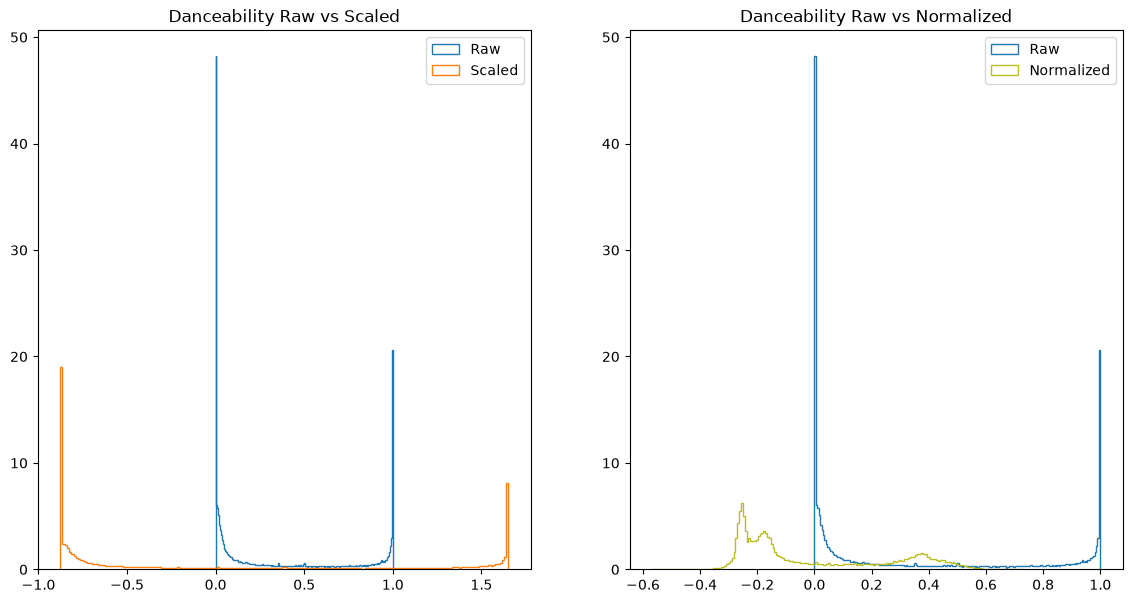

In [136]:
danc_raw = features_raw[:, feature_names == "danceability"].flatten()
dance_scaled = features_scaled[:, feature_names == "danceability"].flatten()
danc_normalized = features_norm[:, feature_names == "danceability"].flatten()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].hist(
    danc_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw"
)
axes[0].hist(
    dance_scaled, bins=200, density=True, histtype="step", color="tab:orange", label="Scaled",
)
axes[0].set_title("Danceability Raw vs Scaled")
axes[0].legend()

axes[1].hist(
    danc_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw"
)
axes[1].hist(
    danc_normalized, bins=200, density=True, histtype="step", color="tab:olive", label="Normalized",
)
axes[1].set_title("Danceability Raw vs Normalized")
axes[1].legend()

plt.legend()
plt.show()

In [137]:
danc_stats_df = pd.DataFrame({
    "min": [danc_raw.min(), dance_scaled.min(), danc_normalized.min()],
    "max": [danc_raw.max(), dance_scaled.max(), danc_normalized.max()],
    "mean": [danc_raw.mean(), dance_scaled.mean(), danc_normalized.mean()],
    "std": [danc_raw.std(), dance_scaled.std(), danc_normalized.std()]
}, index=["raw", "scaled", "normalized"])

with pd.option_context('display.float_format', lambda x: f'{x:,.7f}'):
    display(danc_stats_df)

,min,max,mean,std
raw,0.0000000,0.9999999,0.3467647,0.3952322
scaled,-0.8773696,1.6527882,-0.0000000,1.0000000
normalized,-0.5684434,0.7296201,-0.0041176,0.2658897


In [138]:
near_zero = (danc_raw < 0.01).mean() * 100
near_one = (danc_raw > 0.99).mean() * 100
uncertain = ((danc_raw > 0.4) & (danc_raw < 0.6)).mean() * 100

print(f"Below 0.01: {near_zero:.2f}%")
print(f"Above 0.99: {near_one:.2f}%")
print(f"Uncertain predictions: {uncertain:.2f}%")

Below 0.01: 27.12%
Above 0.99: 11.78%
Uncertain predictions: 6.46%


##### Conclusions
Values for the danceability feature are heavily concentrated at the extremes, ~40% of them being close to either zero or one. Clearly they were generated by a classifier that was determining if a song was danceable or not. The feature doesn't show _how_ danceable the song is.

This brings into question how we should view the features. So far we've assumed they were continuous variables that mapped to some sort of distribution (normal distribution). But the findings show that they're clustered at the extremes.

#### Aggressiveness

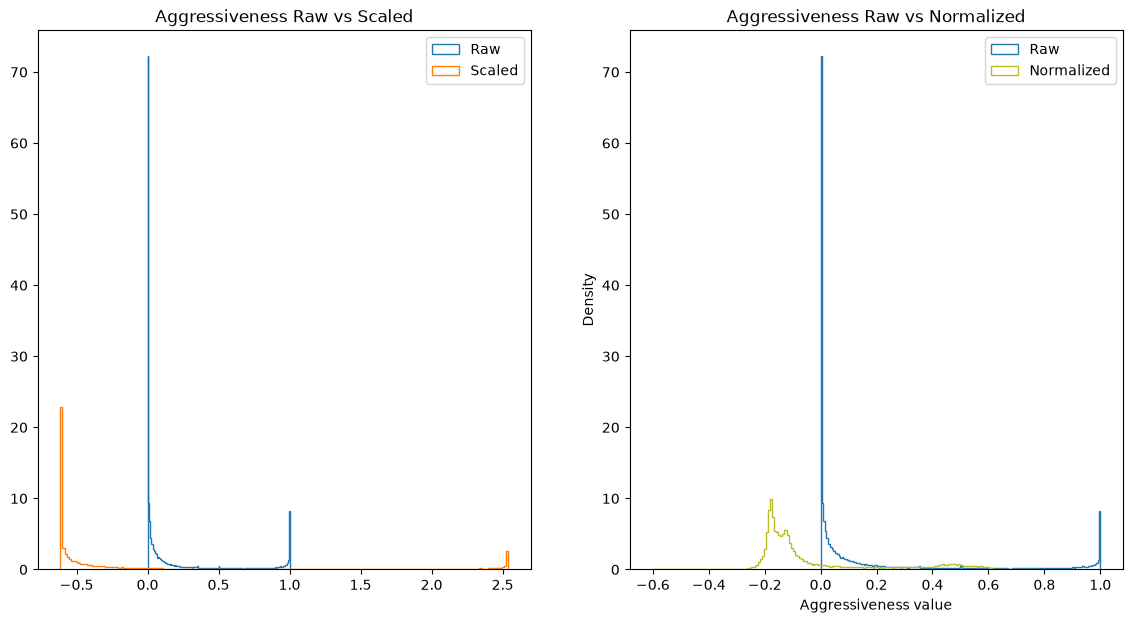

In [139]:
aggr_raw = features_raw[:, feature_names == "aggressiveness"].ravel()
aggr_scaled = features_scaled[:, feature_names == "aggressiveness"].ravel()
aggr_normalized = features_norm[:, feature_names == "aggressiveness"].ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].hist(
    aggr_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw",
)
axes[0].hist(
    aggr_scaled, bins=200, density=True, histtype="step", color="tab:orange", label="Scaled",
)
axes[0].set_title("Aggressiveness Raw vs Scaled")
axes[0].legend()

axes[1].hist(
    aggr_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw",
)
axes[1].hist(
    aggr_normalized, bins=200, density=True, histtype="step", color="tab:olive", label="Normalized",
)
axes[1].set_title("Aggressiveness Raw vs Normalized")
axes[1].legend()


plt.xlabel("Aggressiveness value")
plt.ylabel("Density")
plt.legend()
plt.show()

In [140]:
aggr_stats_df = pd.DataFrame({
    "min": [aggr_raw.min(), aggr_scaled.min(), aggr_normalized.min()],
    "max": [aggr_raw.max(), aggr_scaled.max(), aggr_normalized.max()],
    "mean": [aggr_raw.mean(), aggr_scaled.mean(), aggr_normalized.mean()],
    "std": [aggr_raw.std(), aggr_scaled.std(), danc_normalized.std()]
}, index=["raw", "scaled", "normalized"])

with pd.option_context('display.float_format', lambda x: f'{x:,.7f}'):
    display(aggr_stats_df)

,min,max,mean,std
raw,0.0000000,0.9999999,0.1949158,0.3167960
scaled,-0.6152722,2.5413327,0.0000000,1.0000000
normalized,-0.6030705,0.7805299,-0.0218910,0.2658897


In [141]:
near_zero = (aggr_raw < 0.01).mean() * 100
near_one = (aggr_raw > 0.99).mean() * 100
uncertain = ((aggr_raw > 0.4) & (aggr_raw < 0.6)).mean() * 100

print(f"Below 0.01: {near_zero:.2f}%")
print(f"Above 0.99: {near_one:.2f}%")
print(f"Between 0.4 and 0.6: {uncertain:.2f}%")

Below 0.01: 40.81%
Above 0.99: 4.81%
Between 0.4 and 0.6: 4.16%


In [142]:
# Check the aggressiveness of known aggressive tracks

aggresive_mbids = [
    "62c2e20a-559e-422f-a44c-9afa7882f0c4", "c7c25302-69ab-4a9d-b967-23cbc6793854",
    "06f19a71-ff93-4d95-b7d0-633c4b53eb41", "03cf6e1b-d986-402f-b67e-9fbe2ebc906d",
    "5053c294-90fe-47e9-9e21-1a4c4538c20f", "9190aac9-cbb1-4f26-8b4c-169e08d7897a",
    "37295d29-229a-4609-bb53-0a72e5e0a467", "b1a9c0e9-d987-4042-ae91-78d6a3267d69"
]
aggressive_data = []

for mbid in aggresive_mbids:
    bytes = np.frombuffer(uuid.UUID(mbid).bytes, dtype="V16", count=1)[0]
    index = np.where(feature_store["mbids"] == bytes)[0][0]

    track = Track.objects.filter(musicbrainz_recordingid=mbid).prefetch_related("artists").first()
    if not track:
        continue

    artists = ", ".join(artist.name for artist in track.artists.all())

    aggressive_data.append({
        "title": track.title, "artists": artists,
        "raw": aggr_raw[index], "scaled": aggr_scaled[index], "norm": aggr_normalized[index]
    })

aggr_df = pd.DataFrame(aggressive_data)

with pd.option_context('display.float_format', lambda x: f'{x:,.5f}'):
    display(aggr_df)

,title,artists,raw,scaled,norm
0,Enter Sandman,Metallica,1.00000,2.54133,0.55884
1,Hells Bells,AC/DC,0.83118,2.00844,0.48041
2,Let the Hammer Fall,HammerFall,0.85953,2.09793,0.44572
3,Burning Times,Iced Earth,0.98113,2.48175,0.45423
4,Bad Medicine,Bon Jovi,0.94608,2.37113,0.49182
5,Bed of Roses,Bon Jovi,0.08153,-0.35790,-0.10901
6,2 Minutes to Midnight,Iron Maiden,0.00000,-0.61527,-0.17585
7,Bohemian Rhapsody,Queen,0.05934,-0.42796,-0.21332


##### Conclusions

Like danceability, aggressiveness is also clustered at the extremes. We can assume that most features are like this going forward.

Around 41% of the values are near zero indicating that most tracks don't have an aggressive mood. 
Manual inspection has shown that the feature is accurate: popular heavy-metal tracks rank high in aggressiveness while rock ballads rank low.

The low mean confirms that most values a closer to 0 than 1. Compared to the mean, the relatively large standard deviation indicates that there are large number of tracks scattered across the range, especially at the upper limit.

### Missing Data

#### Missing Release Year

In [143]:
years: npt.NDArray[np.int16] = np.array(feature_store["years"])
num_tracks = len(years)
zero_years = np.sum(years == 0)

print(f"Tracks missing a release year: {zero_years:,} / {num_tracks:,}")

mbids_raw: npt.NDArray[np.void] = feature_store["mbids"]
zero_year_mbids_raw = random.sample(mbids_raw[years == 0].tolist(), 10)
zero_year_mbids = [str(uuid.UUID(bytes=mbid)) for mbid in zero_year_mbids_raw]

zero_year_tracks_qs = (
    Track.objects.filter(musicbrainz_recordingid__in=zero_year_mbids)
    .select_related("album")
    .prefetch_related("artists")
)

zero_year_tracks_df = pd.DataFrame(
    [
        (
            track.musicbrainz_recordingid,
            track.title,
            ", ".join(artist.name for artist in track.artists.all()),
            track.album.name if track.album else "<no album>",
            track.album.date if track.album else None,
        )
        for track in zero_year_tracks_qs
    ],
    columns=["mbid", "title", "artists", "album", "album_date"],
)

print("Sample of tracks missing a release year:")
display(zero_year_tracks_df)

Tracks missing a release year: 1,319 / 85,732
Sample of tracks missing a release year:


,mbid,title,artists,album,album_date
0,24ec06d4-bc65-4b2c-962b-0e64398a54da,The Final Fenix Down,GASHISOFT GXSCC,GASHISOFT 1,None
1,2c9ff286-ab06-4281-a161-e8ce4118a676,Pink Frost,The Chills,"1987-02-20: Melkweg, Amsterdam, Netherlands",None
2,499dfc8f-172a-41b8-805f-52d5ffe394c9,End Credits,Zelda Reorchestrated,A Link to the Past,None
3,75e0c7e9-c4c6-4fc3-9704-884e5cb7f90d,El tiempo,La Gente,Madre,None
4,c6fa2858-f87d-4edc-b452-91610e89014e,Romanze für Violine und Orchester No. 1 in G-D...,Ludwig van Beethoven,"Yehudi Menuhin spielt Brahms, Beethoven, Bruch",None
5,d3f8d07f-aa2d-4b5f-96a2-74069caee01d,President of What,Death Cab for Cutie,"2000-04-14: Crocodile Cafe, Seattle, WA, USA (...",None
6,deb48e94-9bc8-4a14-86c0-21d21818ca8d,King Rat,Bollock Brothers,Twice the Balls,None
7,ede53510-58a0-44d4-82ae-2876b8f420ed,Ana no wa Makkuro ke,パール兄弟,N.H.K ni Youkoso! Sound Collection - Sunny Sid...,None
8,eef17d17-2106-4c66-9326-2968d5d414f1,Frostbite,Subatomic Studios,Fieldrunners Original Soundtrack,None
9,f114bbae-d435-419f-9a0b-9e64d04dd7e8,The Hat Returns & End Credits (Film version),Don Davis,Jurassic Park 3 (Complete),None
